<a href="https://colab.research.google.com/github/LoshithaAI/ML-Assignment/blob/nissanka-hmdp-ms26930190/notebooks/random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Clone the project repository (it contains the dataset in data/data.csv)
!git clone -b nissanka-hmdp-ms26930190 https://github.com/LoshithaAI/ML-Assignment.git

Cloning into 'ML-Assignment'...
remote: Enumerating objects: 201, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 201 (delta 23), reused 0 (delta 0), pack-reused 143 (from 1)
Receiving objects: 100% (201/201), 1.99 MiB | 16.02 MiB/s, done.
Resolving deltas: 100% (75/75), done.


In [3]:
# List the repository contents to confirm the clone worked
!ls ML-Assignment

data  notebooks  README.md  results


# Predicting Student Dropout and Academic Success — Random Forest
**Fundamentals of Machine Learning – Programming Assignment**

| | |
|---|---|
| **Member** | `Nissanka HMDP` (`MS26930190`) |
| **Algorithm** | Random Forest (classification) |
| **Teammate's algorithm** | Logistic Regression (`logistic_regression.ipynb`) |
| **Learning type** | Supervised learning – multi-class classification |


## 1. Setup

In [ ]:
# --- Libraries -------------------------------------------------------------
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, learning_curve)
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [ ]:
# --- Load the dataset ------------------------------------------------------

GITHUB_RAW_URL = "https://raw.githubusercontent.com/LoshithaAI/ML-Assignment/nissanka-hmdp-ms26930190/data/data.csv"

for path in ["data.csv", "data/data.csv", "../data/data.csv"]:
    if os.path.exists(path):
        DATA_PATH = path
        break
else:
    DATA_PATH = GITHUB_RAW_URL
df = pd.read_csv(DATA_PATH, sep=";")
df.columns = df.columns.str.strip()
print("Loaded from:", DATA_PATH)
print("Shape:", df.shape)

Loaded from: https://raw.githubusercontent.com/LoshithaAI/ML-Assignment/nissanka-hmdp-ms26930190/data/data.csv
Shape: (4424, 37)


## 2. Dataset selection and description  

**Dataset:** *Predict Students' Dropout and Academic Success*
**Source (UCI Machine Learning Repository):** https://archive.ics.uci.edu/dataset/697
**License:** CC BY 4.0 &nbsp;|&nbsp; **Citation:** V. Realinho, M. Vieira Martins, J. Machado, and L. Baptista. "Predict Students' Dropout and Academic Success," UCI Machine Learning Repository, 2021. [Online]. Available: https://doi.org/10.24432/C5MC89.

**Context.** The data comes from a Portuguese higher-education institution and combines information known at enrollment
(demographics, socioeconomic background, academic path), the student's academic performance at the end of the 1st and 2nd
semesters, and national macroeconomic indicators. It was created to identify students at risk of dropping out so that
the institution can support them early. Each row is one student enrolled in an undergraduate programme.

**Why it is a suitable dataset**
- Real-world, published online, and hosted on UCI (a credible public repository).
- Not a standard tutorial dataset (unlike Iris/Titanic), and reasonably complex: **4,424 rows, 36 features, 3 classes**.
- Mixed feature types (categorical codes, binary flags, continuous grades) and **imbalanced classes**.

**Target variable:** `Target` – `Dropout`, `Enrolled` or `Graduate` (status at the end of the normal course duration).

**Attributes (36 features + target)**

| Group | Attributes | Type |
|---|---|---|
| Demographic | Marital status, Nacionality, Gender, Age at enrollment, International, Displaced | Categorical code / binary / numeric |
| Application | Application mode, Application order, Course, Daytime/evening attendance | Categorical code / ordinal / binary |
| Previous education | Previous qualification, Previous qualification (grade), Admission grade | Categorical code / numeric |
| Family background | Mother's qualification, Father's qualification, Mother's occupation, Father's occupation | Categorical code |
| Financial / special | Educational special needs, Debtor, Tuition fees up to date, Scholarship holder | Binary |
| 1st-semester performance | Curricular units 1st sem (credited, enrolled, evaluations, approved, grade, without evaluations) | Numeric |
| 2nd-semester performance | Curricular units 2nd sem (credited, enrolled, evaluations, approved, grade, without evaluations) | Numeric |
| Macroeconomic | Unemployment rate, Inflation rate, GDP | Numeric |

> The code-valued columns (Marital status, Application mode, Course, Previous qualification, Nacionality, parents'
> qualification and occupation) are **integer labels for categories, not quantities**. The lookup tables are on the UCI page.

In [ ]:
display(df.head())
print("Rows, columns:", df.shape)
print("Features:", df.shape[1] - 1, "| Target: Target")

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Rows, columns: (4424, 37)
Features: 36 | Target: Target


          count  percent
Target                  
Graduate   2209     49.9
Dropout    1421     32.1
Enrolled    794     17.9


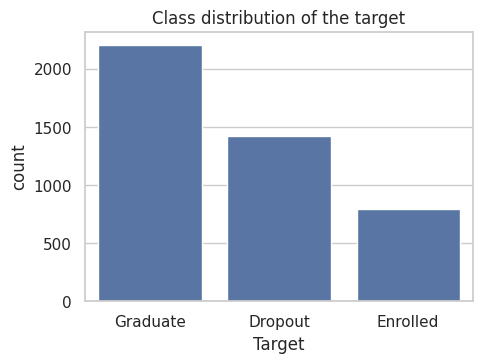

In [ ]:
# Class distribution of the target
counts = df["Target"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}))

plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x="Target", order=counts.index)
plt.title("Class distribution of the target")
plt.show()

In [ ]:
# Group the columns by type
cat_cols = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
            "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binary_cols = [c for c in df.columns if c not in cat_cols + ["Target"] and df[c].nunique() <= 2]
num_cols = [c for c in df.columns if c not in cat_cols + binary_cols + ["Target", "Application order"]]

print("Categorical-code columns :", len(cat_cols))
print("Binary (0/1) columns     :", len(binary_cols))
print("Continuous columns       :", len(num_cols))
df[num_cols].describe().T.round(2)

Categorical-code columns : 9
Binary (0/1) columns     : 8
Continuous columns       : 18


,count,mean,std,min,25%,50%,75%,max
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00
Curricular units 2nd sem (credited),4424.0,0.54,1.92,0.00,0.00,0.00,0.00,19.00


## 3. Data preprocessing  

### 3.1 Data cleansing

In [ ]:
print("Missing values (total):", int(df.isna().sum().sum()))
print("Duplicate rows        :", int(df.duplicated().sum()))
print("Non-numeric columns   :", list(df.select_dtypes(exclude="number").columns))

Missing values (total): 0
Duplicate rows        : 0
Non-numeric columns   : ['Target']


**Finding:** no missing values and no duplicates, so no imputation or row removal is needed. The only cleaning needed was
the semicolon delimiter and removing whitespace from the column names.

### 3.2 Outlier analysis

,feature,n_outliers,percent
13,Curricular units 2nd sem (grade),877,19.8
7,Curricular units 1st sem (grade),726,16.4
3,Curricular units 1st sem (credited),577,13.0
9,Curricular units 2nd sem (credited),530,12.0
2,Age at enrollment,441,10.0
4,Curricular units 1st sem (enrolled),424,9.6
10,Curricular units 2nd sem (enrolled),369,8.3
8,Curricular units 1st sem (without evaluations),294,6.6


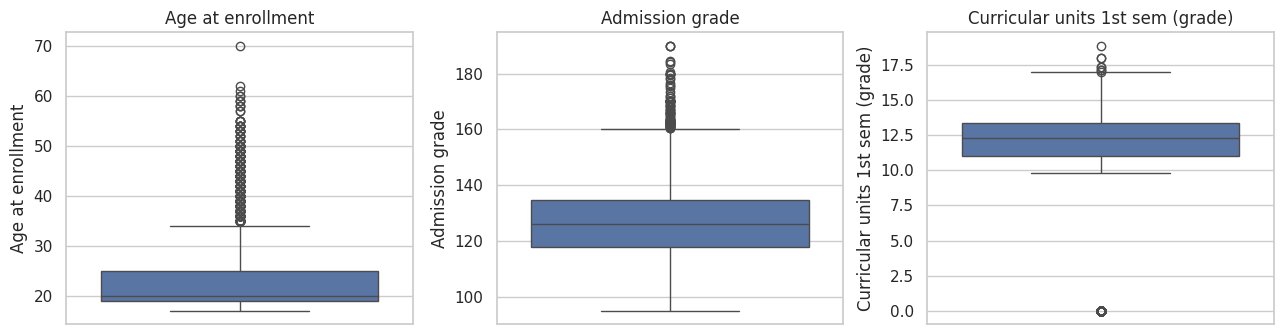

In [ ]:
# IQR rule: values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR] are flagged as potential outliers
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append((c, n_out, round(n_out / len(df) * 100, 1)))
outliers = pd.DataFrame(rows, columns=["feature", "n_outliers", "percent"]).sort_values("n_outliers", ascending=False)
display(outliers.head(8))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes, ["Age at enrollment", "Admission grade", "Curricular units 1st sem (grade)"]):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Decision:**
The IQR rule flagged many values, mainly in 2nd-semester grade (19.8%), 1st-semester grade (16.4%), credited units (12 to 13%) and age at enrollment (10.0%). These are genuine observations, such as mature students and students who passed no units, not data-entry errors, so all outliers are kept. Removing them would discard useful information, and Random Forest is robust to outliers because trees split on thresholds rather than on how extreme a value is.

### 3.3 Exploratory analysis

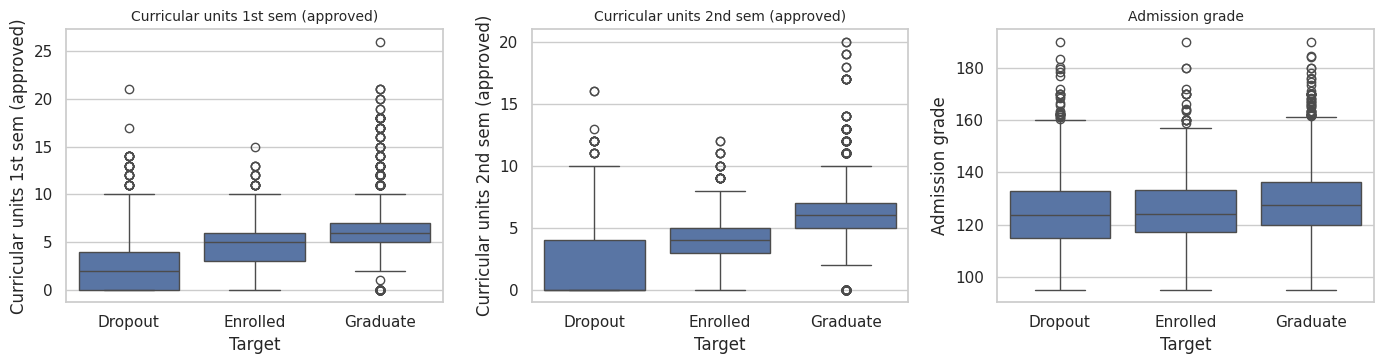

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, ["Curricular units 1st sem (approved)",
                        "Curricular units 2nd sem (approved)",
                        "Admission grade"]):
    sns.boxplot(data=df, x="Target", y=c, order=["Dropout", "Enrolled", "Graduate"], ax=ax)
    ax.set_title(c, fontsize=10)
plt.tight_layout()
plt.show()

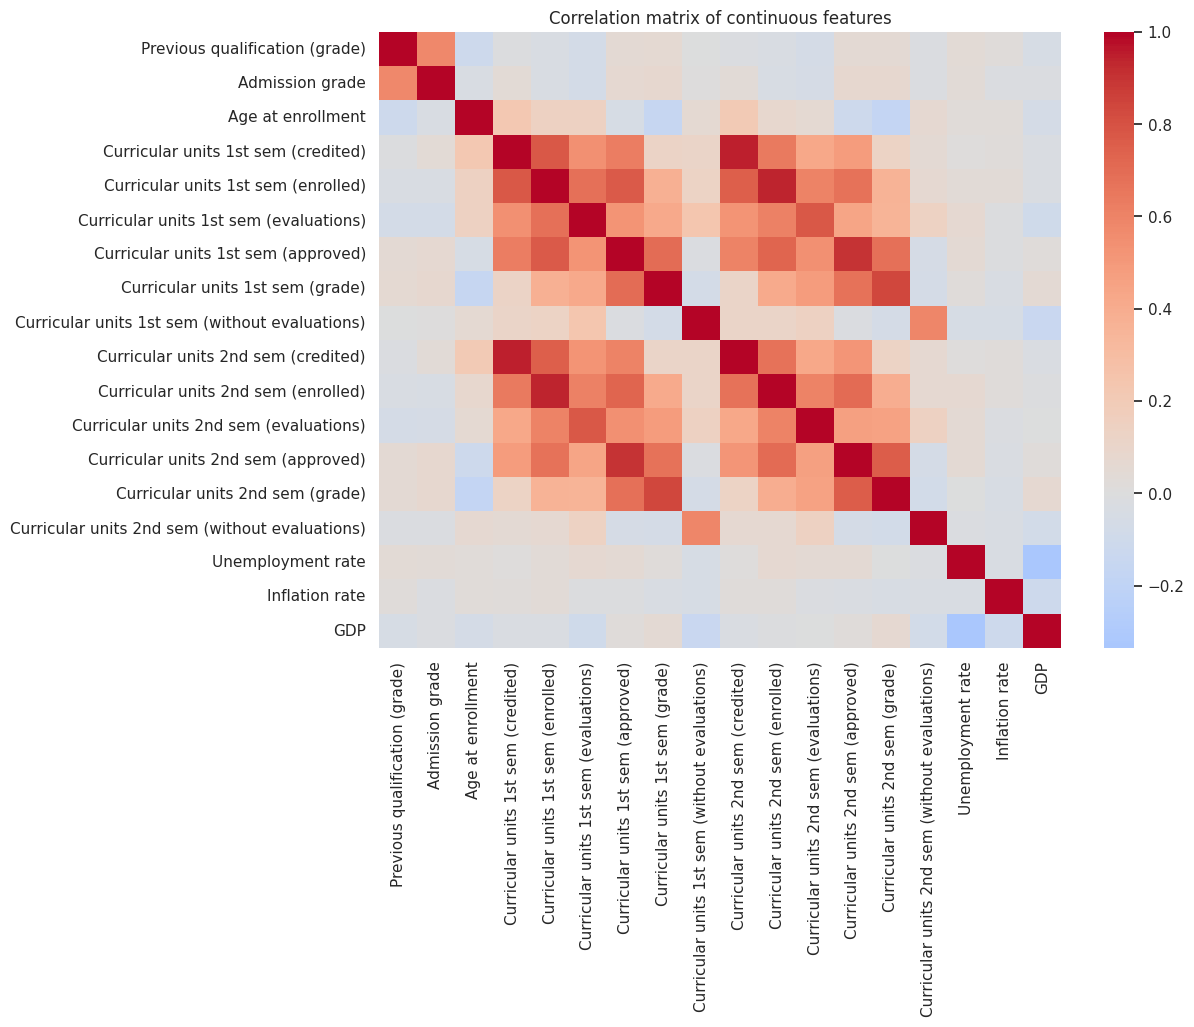

In [ ]:
# Creating Correlation matrix

plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation matrix of continuous features")
plt.show()

**Observations:**

*   Approved units separate the classes clearly. Graduates have a median of 6 approved units in both semesters, while Dropouts have 2 in the 1st semester and 0 in the 2nd. Enrolled students sit in between (5 and 4).

*   Admission grade is a weak separator on its own. The medians are close (123.6 Dropout, 124.1 Enrolled, 127.4 Graduate) and the boxes overlap heavily.

*   “Enrolled” lies between the other two classes on every    feature, which suggests it will be the hardest class to predict.

*   1st- and 2nd-semester features are strongly correlated (0.78 to 0.94 for the matching pairs), so they carry partly redundant information and share feature importance










### 3.4 Encoding categorical features

The nine code-valued columns are **labels, not quantities**. They are **one-hot encoded** so that the model never treats
`Course = 9254` as "larger" than `Course = 171`.
`drop_first=True` removes one redundant dummy per feature.

In [ ]:
X = pd.get_dummies(df.drop(columns="Target"), columns=cat_cols, drop_first=True)
y = df["Target"]
print("Features before encoding:", df.shape[1] - 1)
print("Features after encoding :", X.shape[1])

Features before encoding: 36
Features after encoding : 238


### 3.5 Train/test split

In [ ]:
# 80/20 split, STRATIFIED so each part keeps the same class proportions.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class %:", (y_train.value_counts(normalize=True) * 100).round(1).to_dict())
print("Test  class %:", (y_test.value_counts(normalize=True) * 100).round(1).to_dict())

Train: (3539, 238) | Test: (885, 238)
Train class %: {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 17.9}
Test  class %: {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 18.0}


### 3.6 Feature scaling

Scaling is not needed for Random Forest. Each tree split only asks whether a feature is above or below a threshold, which depends on the order of the values and not on their scale. The same unscaled X_train and X_test are therefore used for all models in this notebook. Logistic Regression, by contrast, needs standardised inputs.

### 3.7 Dimensionality reduction (feature selection)

After one-hot encoding there are 238 columns, and many are rare dummies. Rather than PCA (which would make the features
uninterpretable), **feature selection by importance** is used. A forest is fitted, features are ranked by importance, and
Section 7 tests whether keeping only the top features keeps accuracy while simplifying the model.

## 4. Algorithm background and justification  

### 4.1 What is a Random Forest?
A Random Forest is a **supervised ensemble algorithm** that builds many **decision trees** and combines their votes.

**Decision tree.** A tree repeatedly splits the data with simple yes/no questions (e.g. "approved units in 2nd semester ≤ 4?").
At each node it chooses the split that makes the resulting groups as *pure* as possible, measured by **Gini impurity**:
Gini = 1 − Σ p<sub>k</sub><sup>2</sup>, where p<sub>k</sub> is the share of class *k* in the node. Each leaf predicts the majority class.
A single deep tree fits the training data very closely and **overfits** (high variance).

**Random Forest fixes this with two sources of randomness:**
1. **Bagging (bootstrap aggregating):** each tree is trained on a random sample of the rows drawn *with replacement*.
2. **Random feature subsets:** at each split only a random subset of features (`max_features`) is considered, which makes the trees different from each other (de-correlated).

The final prediction is the **majority vote** (or averaged class probabilities) of all trees. Averaging many different, high-variance trees
gives a model with **much lower variance** and better generalisation. The rows left out of each bootstrap sample give a free
**out-of-bag (OOB)** accuracy estimate.

### 4.2 Why it suits this dataset
- It handles **mixed feature types** and **non-linear relationships and interactions** (e.g. scholarship × debt × grades) without manual feature engineering.
- It needs **no feature scaling** and is **robust to outliers**.
- It copes well with **many features** (238 after encoding) including correlated ones.
- It supports **class weighting** for the imbalanced "Enrolled" class.
- It provides **feature importance**, so the institution can see which factors drive dropout.
- It contrasts clearly with the **Logistic Regression** model (non-linear tree ensemble vs. linear model), which makes the comparison meaningful.

### 4.3 Limitations
Less interpretable than a linear model (hundreds of trees), slower to train and predict, and impurity-based importances can be biased toward
features with many distinct values. It can still overfit noisy data if trees are left unrestricted.

### 4.4 Hyperparameters tuned
| Hyperparameter | Meaning | Values searched |
|---|---|---|
| `n_estimators` | Number of trees | 100, 200, 300, 500 |
| `max_depth` | Maximum depth of each tree (controls overfitting) | None, 8, 12, 16, 24 |
| `min_samples_leaf` | Minimum samples in a leaf (smoother trees) | 1, 2, 4, 8 |
| `max_features` | Features considered per split | `"sqrt"`, `"log2"`, 0.3 |
| `class_weight` | Penalise mistakes on small classes more | `None`, `"balanced"`, `"balanced_subsample"` |

Search method: **RandomizedSearchCV** (20 random combinations, 5-fold stratified CV on the training set), scored by **macro-F1** because
accuracy alone hides poor performance on the small "Enrolled" class.

## 5. Model implementation  

### 5.1 Baseline model

In [ ]:
baseline = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

base_acc = accuracy_score(y_test, pred_base)
base_f1 = f1_score(y_test, pred_base, average="macro")
print(f"Baseline  accuracy = {base_acc:.3f} | macro-F1 = {base_f1:.3f}")

Baseline  accuracy = 0.766 | macro-F1 = 0.668


### 5.2 Hyperparameter tuning (cross-validation on the training set only)

In [ ]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 8, 12, 16, 24],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.3],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist, n_iter=20, cv=cv,
    scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=1, return_train_score=True)
search.fit(X_train, y_train)

print("Best parameters  :", search.best_params_)
print(f"Best CV macro-F1 : {search.best_score_:.3f}")

cv_results = (pd.DataFrame(search.cv_results_)
              [["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_max_features",
                "param_class_weight", "mean_train_score", "mean_test_score"]]
              .sort_values("mean_test_score", ascending=False))
display(cv_results.round(3).head(8))

Best parameters  : {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': 'balanced'}
Best CV macro-F1 : 0.717


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,param_class_weight,mean_train_score,mean_test_score
9,300,16,2,sqrt,balanced,0.923,0.717
14,300,16,8,0.3,balanced,0.825,0.713
15,100,8,4,0.3,balanced,0.799,0.712
0,100,12,2,sqrt,balanced,0.861,0.712
4,200,24,2,log2,balanced,0.882,0.707
17,500,16,1,sqrt,balanced_subsample,0.980,0.705
1,300,8,1,sqrt,balanced,0.788,0.704
8,100,8,2,sqrt,balanced,0.771,0.704


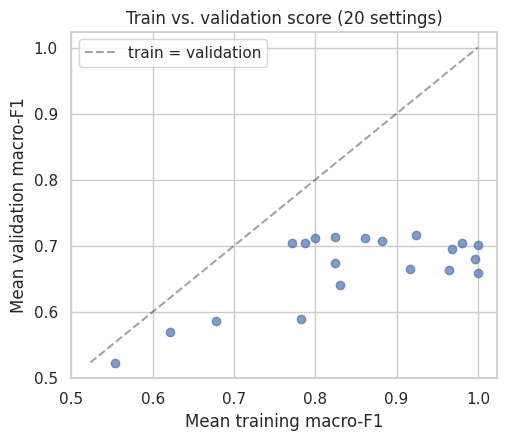

In [ ]:
# Overfitting check: train vs. validation score across all tried settings
plt.figure(figsize=(5.5, 4.5))
plt.scatter(cv_results["mean_train_score"], cv_results["mean_test_score"], alpha=0.7)
lo, hi = cv_results[["mean_test_score", "mean_train_score"]].min().min(), 1.0
plt.plot([lo, hi], [lo, hi], "k--", alpha=0.4, label="train = validation")
plt.xlabel("Mean training macro-F1"); plt.ylabel("Mean validation macro-F1")
plt.title("Train vs. validation score (20 settings)"); plt.legend()
plt.show()

**Reading the plot:**

Every point lies to the right of the dashed line, so all 20 settings score higher on the training folds than on the validation folds, which means some overfitting is present in all of them. The gap is largest for deep, unrestricted trees: the setting with min_samples_leaf=1 reaches a training macro-F1 of 0.980 but only 0.705 on validation. Shallower or more restricted settings (for example max_depth=8, training 0.771 to 0.799) have a much smaller gap, but their validation scores are about the same (0.704 to 0.712). The best setting (300 trees, max_depth=16, min_samples_leaf=2, class_weight="balanced") gives the highest validation macro-F1 of 0.717. It still has a training score of 0.923, so a gap remains. Tuning therefore improved validation performance only slightly (the top settings differ by about 0.01), and the main gains came from using class weights and limiting tree depth and leaf size.

## 6. Results on the held-out test set  
The test set was **not used** for any tuning decision. It is evaluated once, with the final tuned model.

In [ ]:
#final tuned model
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)
classes = list(best_model.classes_)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
print(f"Test accuracy : {test_acc:.3f}")
print(f"Test macro-F1 : {test_f1:.3f}")
print()
print(classification_report(y_test, y_pred, digits=3))

Test accuracy : 0.759
Test macro-F1 : 0.703

              precision    recall  f1-score   support

     Dropout      0.812     0.715     0.760       284
    Enrolled      0.474     0.509     0.491       159
    Graduate      0.836     0.878     0.857       442

    accuracy                          0.759       885
   macro avg      0.707     0.701     0.703       885
weighted avg      0.763     0.759     0.760       885



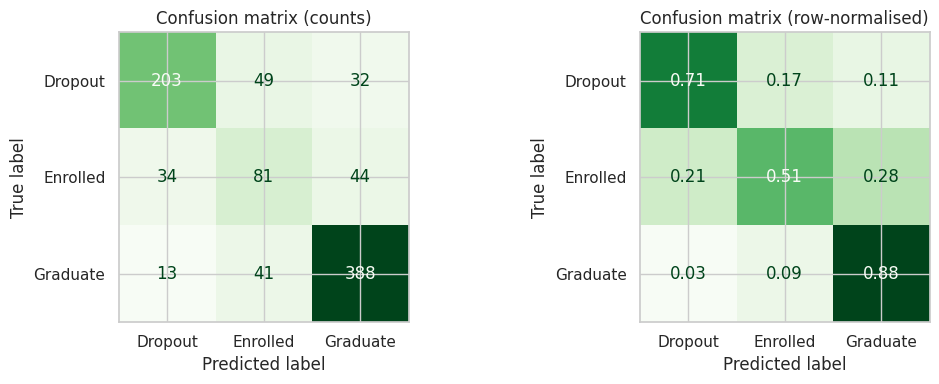

In [ ]:
#confusion matix
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap="Greens", colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", ax=axes[1],
                                        cmap="Greens", colorbar=False, values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalised)")
plt.tight_layout()
plt.show()

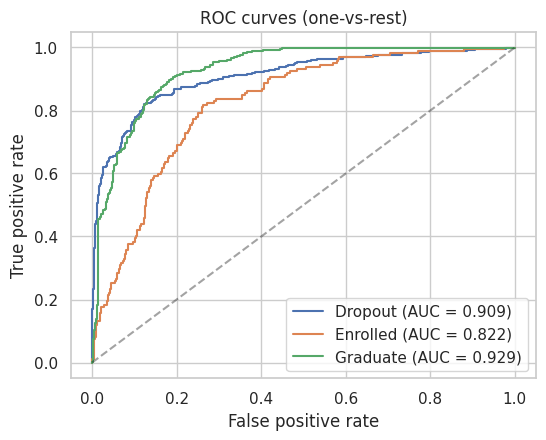

Macro-average AUC (OvR): 0.887


In [ ]:
# One-vs-rest ROC curves and AUC
y_bin = label_binarize(y_test, classes=classes)
plt.figure(figsize=(6, 4.5))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC = {roc_auc_score(y_bin[:, i], y_proba[:, i]):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (one-vs-rest)"); plt.legend()
plt.show()

macro_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
print(f"Macro-average AUC (OvR): {macro_auc:.3f}")

In [ ]:
# Stability check: 5-fold CV of the final model on the TRAINING data
cv_acc = cross_val_score(best_model, X_train, y_train, cv=cv, scoring="accuracy")
cv_f1 = cross_val_score(best_model, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"CV accuracy : {cv_acc.mean():.3f} +/- {cv_acc.std():.3f}")
print(f"CV macro-F1 : {cv_f1.mean():.3f} +/- {cv_f1.std():.3f}")

# Out-of-bag estimate -> free validation score built into Random Forest
oob_model = RandomForestClassifier(**{**search.best_params_, "oob_score": True,
                                      "random_state": RANDOM_STATE, "n_jobs": -1}).fit(X_train, y_train)
print(f"OOB accuracy: {oob_model.oob_score_:.3f}")

CV accuracy : 0.771 +/- 0.015
CV macro-F1 : 0.717 +/- 0.020
OOB accuracy: 0.769


In [ ]:
# Summary table: baseline vs. tuned model
summary = pd.DataFrame({
    "Model": ["Random Forest (baseline)", "Random Forest (tuned)"],
    "Accuracy": [base_acc, test_acc],
    "Macro-F1": [base_f1, test_f1],
    "Macro-Precision": [precision_score(y_test, pred_base, average="macro"), precision_score(y_test, y_pred, average="macro")],
    "Macro-Recall": [recall_score(y_test, pred_base, average="macro"), recall_score(y_test, y_pred, average="macro")],
}).round(3)
summary

,Model,Accuracy,Macro-F1,Macro-Precision,Macro-Recall
0,Random Forest (baseline),0.766,0.668,0.718,0.660
1,Random Forest (tuned),0.759,0.703,0.707,0.701


**Result Discussion:**

The baseline forest has slightly higher accuracy (0.766 vs 0.759) and macro-precision (0.718 vs 0.707). The tuned forest is better on macro-F1 (0.703 vs 0.668) and macro-recall (0.701 vs 0.660). The accuracy difference is small (about 0.7 percentage points on 885 test students) and within normal sampling noise. The baseline reaches its accuracy mostly by predicting the large Graduate and Dropout classes well, while its recall on the minority “Enrolled” class is weak. The tuned model, which uses balanced class weights, trades a little precision and accuracy for better recall across all three classes. Because macro-averaged metrics treat each class equally, the tuned model is the better choice here, even though it does not improve accuracy.

### 6.1 Model interpretation

Top 15 features (impurity-based importance):


,0
Curricular units 2nd sem (approved),0.1202
Curricular units 2nd sem (grade),0.0990
Curricular units 1st sem (approved),0.0828
Curricular units 1st sem (grade),0.0677
Curricular units 2nd sem (evaluations),0.0500
Curricular units 1st sem (evaluations),0.0458
Tuition fees up to date,0.0427
Age at enrollment,0.0380
Admission grade,0.0344
Previous qualification (grade),0.0290


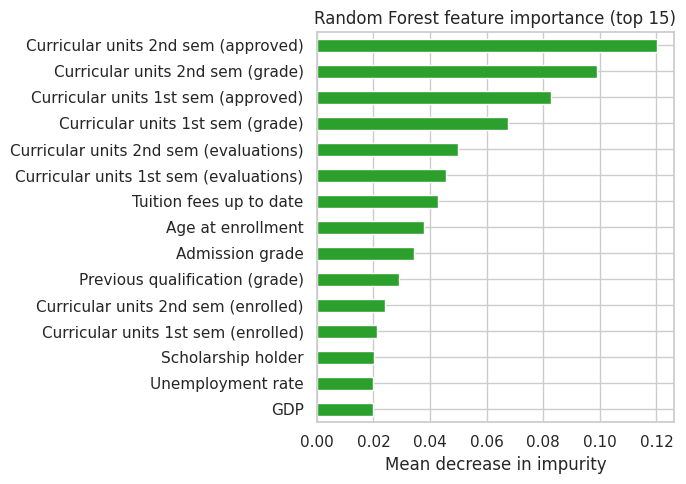

In [ ]:
# (a) Impurity-based importance (fast, but can favour features with many distinct values)
imp = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("Top 15 features (impurity-based importance):")
display(imp.head(15).round(4))

plt.figure(figsize=(7, 5))
imp.head(15).sort_values().plot(kind="barh", color="tab:green")
plt.title("Random Forest feature importance (top 15)")
plt.xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.show()

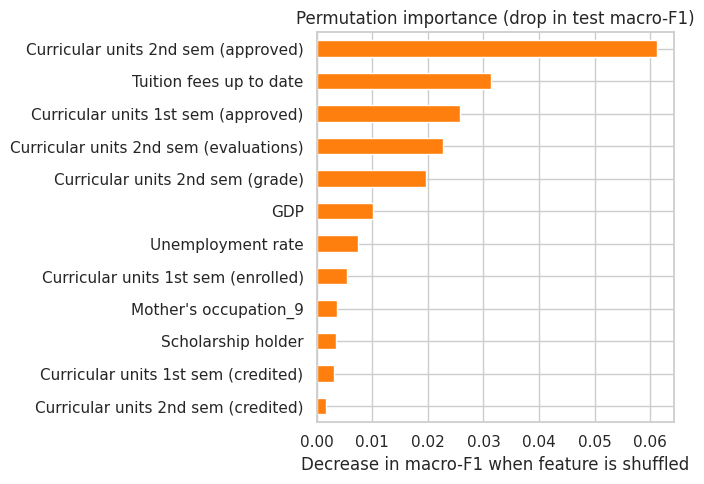

In [ ]:
# (b) Permutation importance on the TEST set (more reliable): how much does macro-F1 drop when one feature's values are shuffled?
top_feats = list(imp.head(25).index)
perm_model = RandomForestClassifier(**{**search.best_params_, "random_state": RANDOM_STATE, "n_jobs": -1})
perm_model.fit(X_train, y_train)
base_score = f1_score(y_test, perm_model.predict(X_test), average="macro")

rng = np.random.RandomState(RANDOM_STATE)
drops = {}
for f in top_feats:
    scores = []
    for _ in range(3):
        Xp = X_test.copy()
        Xp[f] = rng.permutation(Xp[f].values)
        scores.append(f1_score(y_test, perm_model.predict(Xp), average="macro"))
    drops[f] = base_score - np.mean(scores)

perm = pd.Series(drops).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
perm.head(12).sort_values().plot(kind="barh", color="tab:orange")
plt.title("Permutation importance (drop in test macro-F1)")
plt.xlabel("Decrease in macro-F1 when feature is shuffled")
plt.tight_layout()
plt.show()

**Plot Explanation :**

Both plots show that academic performance drives the model. In the impurity plot, the top four features are 2nd-semester approved units, 2nd-semester grade, 1st-semester approved units and 1st-semester grade. The permutation plot agrees on the top feature: shuffling 2nd-semester approved units causes by far the largest drop in macro-F1 (about 0.06). Tuition fees up to date ranks second under permutation (about 0.03) but only seventh by impurity, so it matters more for actual predictions than its split counts suggest. Demographic features contribute little. Permutation importance is the more reliable guide, since impurity importance can favour features with many distinct values.

In [ ]:
# Save results to be compared with the Logistic Regression results
os.makedirs("results", exist_ok=True)
results = {
    "model": "Random Forest",
    "best_params": {k: (None if v is None else (v if isinstance(v, (str, float)) else int(v)))
                    for k, v in search.best_params_.items()},
    "test_accuracy": round(float(test_acc), 4),
    "test_macro_f1": round(float(test_f1), 4),
    "test_macro_auc_ovr": round(float(macro_auc), 4),
    "cv_macro_f1_mean": round(float(cv_f1.mean()), 4),
    "per_class": classification_report(y_test, y_pred, output_dict=True, digits=4),
}
with open("results/random_forest_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved results/random_forest_results.json")

Saved results/random_forest_results.json


### 6.2 Comparison with Logistic Regression

In [ ]:
# Reads both results files and compare
rows = []
for name, path in [("Logistic Regression", "results/logistic_regression_results.json"),
                   ("Random Forest", "results/random_forest_results.json")]:
    if os.path.exists(path):
        r = json.load(open(path))
        pc = r["per_class"]
        rows.append({"Model": name, "Accuracy": r["test_accuracy"], "Macro-F1": r["test_macro_f1"],
                     "Macro-AUC": r["test_macro_auc_ovr"],
                     "F1 Dropout": round(pc["Dropout"]["f1-score"], 3),
                     "F1 Enrolled": round(pc["Enrolled"]["f1-score"], 3),
                     "F1 Graduate": round(pc["Graduate"]["f1-score"], 3)})
    else:
        print(f"{path} not found yet - run the other notebook first.")
pd.DataFrame(rows)

,Model,Accuracy,Macro-F1,Macro-AUC,F1 Dropout,F1 Enrolled,F1 Graduate
0,Logistic Regression,0.7345,0.6961,0.8844,0.751,0.504,0.834
1,Random Forest,0.7593,0.7026,0.8866,0.760,0.491,0.857


## 7. Critical analysis and discussion


In [ ]:
#Improvement experiments
tuned = dict(search.best_params_)
experiments = {}

def evaluate(name, params, Xtr, Xte):
    m = RandomForestClassifier(**{**params, "random_state": RANDOM_STATE, "n_jobs": -1}).fit(Xtr, y_train)
    p = m.predict(Xte)
    experiments[name] = {"Accuracy": accuracy_score(y_test, p),
                         "Macro-F1": f1_score(y_test, p, average="macro"),
                         "Enrolled recall": recall_score(y_test, p, labels=["Enrolled"], average=None)[0]}
    return m

# E0: tuned model (reference)
evaluate("E0 Tuned model (reference)", tuned, X_train, X_test)

# E1: no class weights
evaluate("E1 Without class_weight", {**tuned, "class_weight": None}, X_train, X_test)

# E2: default hyperparameters (what tuning changed)
evaluate("E2 Default hyperparameters", {}, X_train, X_test)

# E3: raw integer codes instead of one-hot (trees can split on codes directly)
X_raw = df.drop(columns="Target")
Xr_train, Xr_test, _, _ = train_test_split(X_raw, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
evaluate("E3 Raw codes (no one-hot)", tuned, Xr_train, Xr_test)

# E4: feature selection - keep only the 30 most important features
top30 = list(imp.head(30).index)
evaluate("E4 Top-30 features only", tuned, X_train[top30], X_test[top30])

# E5: EARLY prediction - remove all 1st/2nd-semester performance features
early_cols = [c for c in X_train.columns if not c.startswith("Curricular units")]
evaluate("E5 Early prediction (no semester data)", tuned, X_train[early_cols], X_test[early_cols])

# E6: only information up to the 1st semester
sem1_cols = [c for c in X_train.columns if not c.startswith("Curricular units 2nd sem")]
evaluate("E6 Up to 1st semester only", tuned, X_train[sem1_cols], X_test[sem1_cols])

exp_table = pd.DataFrame(experiments).T.round(3)
exp_table

,Accuracy,Macro-F1,Enrolled recall
E0 Tuned model (reference),0.759,0.703,0.509
E1 Without class_weight,0.767,0.657,0.226
E2 Default hyperparameters,0.766,0.668,0.270
E3 Raw codes (no one-hot),0.764,0.704,0.484
E4 Top-30 features only,0.772,0.718,0.522
E5 Early prediction (no semester data),0.615,0.557,0.340
E6 Up to 1st semester only,0.715,0.654,0.428


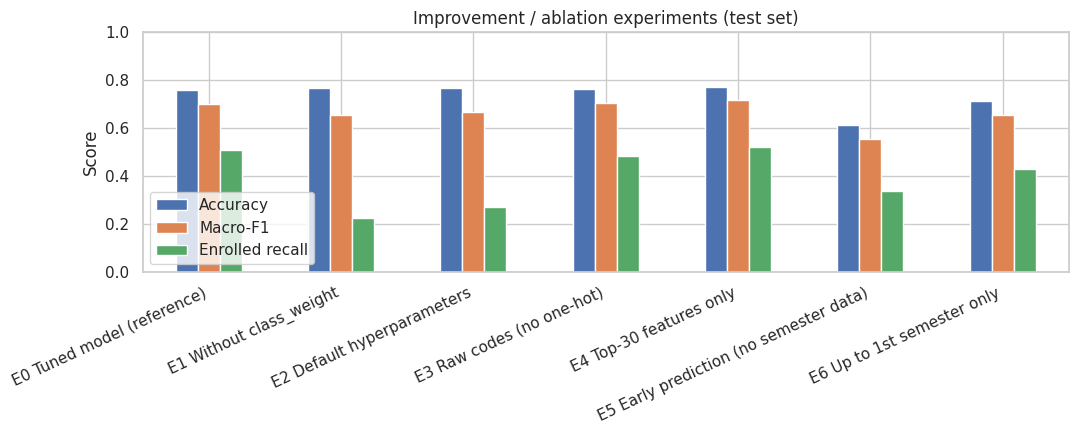

In [ ]:
#Bar chart comparing experiments
exp_table[["Accuracy", "Macro-F1", "Enrolled recall"]].plot(kind="bar", figsize=(11, 4.5))
plt.title("Improvement / ablation experiments (test set)")
plt.ylabel("Score"); plt.ylim(0, 1); plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

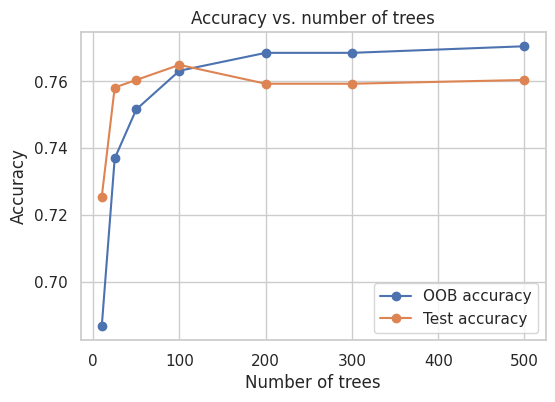

In [ ]:
# Effect of the NUMBER OF TREES
tree_counts = [10, 25, 50, 100, 200, 300, 500]
oob_scores, test_scores = [], []
for n in tree_counts:
    m = RandomForestClassifier(**{**tuned, "n_estimators": n, "oob_score": True,
                                  "random_state": RANDOM_STATE, "n_jobs": -1}).fit(X_train, y_train)
    oob_scores.append(m.oob_score_)
    test_scores.append(accuracy_score(y_test, m.predict(X_test)))

plt.figure(figsize=(6, 4))
plt.plot(tree_counts, oob_scores, marker="o", label="OOB accuracy")
plt.plot(tree_counts, test_scores, marker="o", label="Test accuracy")
plt.xlabel("Number of trees"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Accuracy vs. number of trees")
plt.show()

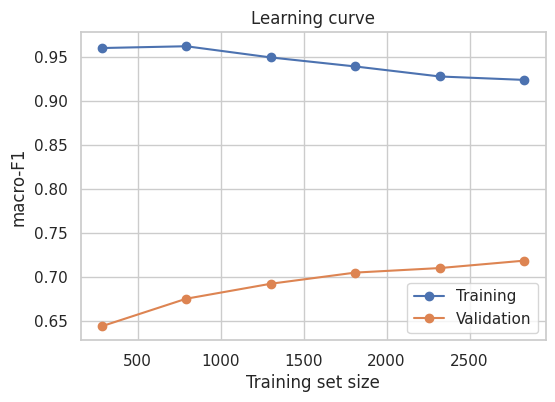

In [ ]:
# Learning curve
sizes, tr_scores, va_scores = learning_curve(
    RandomForestClassifier(**{**tuned, "random_state": RANDOM_STATE, "n_jobs": -1}), X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 6), cv=cv, scoring="f1_macro", n_jobs=1)

plt.figure(figsize=(6, 4))
plt.plot(sizes, tr_scores.mean(axis=1), marker="o", label="Training")
plt.plot(sizes, va_scores.mean(axis=1), marker="o", label="Validation")
plt.xlabel("Training set size"); plt.ylabel("macro-F1"); plt.legend()
plt.title("Learning curve")
plt.show()

**Interpretation of the improvement experiments**



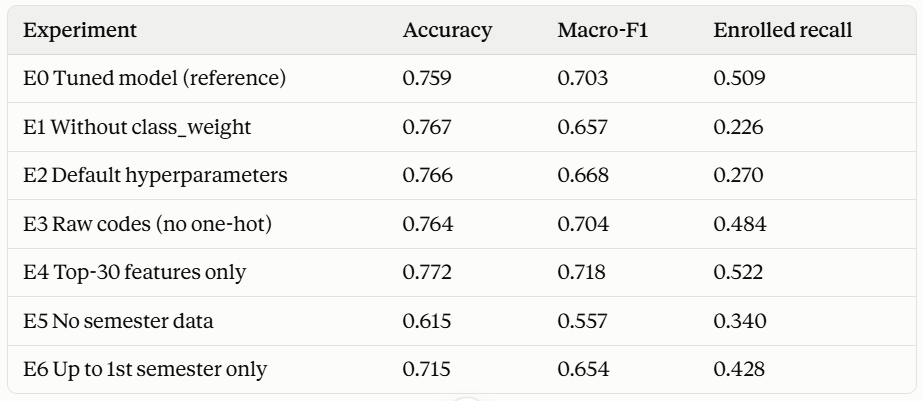




*   Class weights (E0 vs E1): Removing them raises accuracy slightly (0.767 vs 0.759) but lowers macro-F1 (0.657 vs 0.703). Enrolled recall also falls from 0.509 to 0.226, so the model almost ignores the minority class. Balanced weights cost a little accuracy but are the main reason the tuned model finds more of the students who are neither dropping out nor graduating.

*   Tuning (E0 vs E2): Tuning did not raise accuracy (0.759 vs 0.766), but it improved macro-F1 (0.703 vs 0.668) and Enrolled recall (0.509 vs 0.270). Most of the gain comes from class weighting, not from the other hyperparameters.

*   One-hot encoding vs raw codes (E3): The two are almost identical (0.759 vs 0.764 accuracy, 0.703 vs 0.704 macro-F1). The simpler encoding keeps the same performance with far fewer columns.

*   Feature selection (E4): Keeping only the top 30 features gave the best scores in the table (0.772 accuracy, 0.718 macro-F1). Many of the 238 columns add noise. This is a small gain, and because the 30 features were chosen from the data, it should be treated as a suggestion for future work, not as the final model.

*   Early prediction (E5, E6): Without any semester data, accuracy drops to 0.615 and macro-F1 to 0.557. With only 1st-semester data, accuracy recovers to 0.715. Most of the predictive power comes from academic results after enrolment, so predicting at enrolment time is much harder. Each extra semester of data adds a lot, which matters for any early-warning system.


### 7.1 Discussion



1. Overall performance: The tuned forest reaches 0.759 accuracy, 0.703 macro-F1 and 0.887 macro-AUC. That is far above the always-“Graduate” baseline of about 50%. The default forest scores 0.766 accuracy but only 0.668 macro-F1, so tuning mainly improved the balance between classes.

2. Per-class behaviour: Graduate is predicted best (F1 0.857, 388 of 442 correct) and Dropout next (F1 0.760, 203 of 284 correct). Enrolled is hardest (F1 0.491, 81 of 159 correct). Its students are mostly confused with Graduate (44) and Dropout (34), because they sit between the two groups.

3. Class weights: Removing them gives slightly higher accuracy (0.767 vs 0.759), but Enrolled recall falls from 0.509 to 0.226 and macro-F1 from 0.703 to 0.657. For an institution that wants to find at-risk students, recall on the minority class matters more than a small gain in accuracy, so keeping the weights is better.

4. Tuning: On the test set, tuning did not raise accuracy (0.759 vs 0.766 for default), but it raised macro-F1 (0.703 vs 0.668), mainly through class weighting. The training folds score 0.923 against 0.717 on validation, so the model still overfits somewhat despite the depth and leaf limits.

5. Simpler representations: Raw codes perform the same as one-hot encoding (0.764 accuracy, 0.704 macro-F1). Keeping only the top 30 features gives the best scores (0.772 accuracy, 0.718 macro-F1), so a much simpler model does not lose performance. Since those features were chosen from the data, this is a suggestion rather than a final model.

6. Early prediction: Without semester data, accuracy falls to 0.615 and macro-F1 to 0.557. With only 1st-semester data it recovers to 0.715. Most of the predictive power comes from results after enrolment, which limits how early the model can warn.

7. Feature importance: The top features are approved units, grades and tuition fees up to date, which fit common sense. 1st- and 2nd-semester features are correlated and share importance, so individual scores should not be over-interpreted.

8. Trees and data: OOB accuracy rises from 0.687 (10 trees) to 0.763 (100 trees) and levels off at about 0.77 after 200 trees, so 300 trees is enough. In the learning curve, validation macro-F1 is still rising slowly (0.644 to 0.719) and the train/validation gap narrows, so more data would probably help a little.

9. Comparison with Logistic Regression
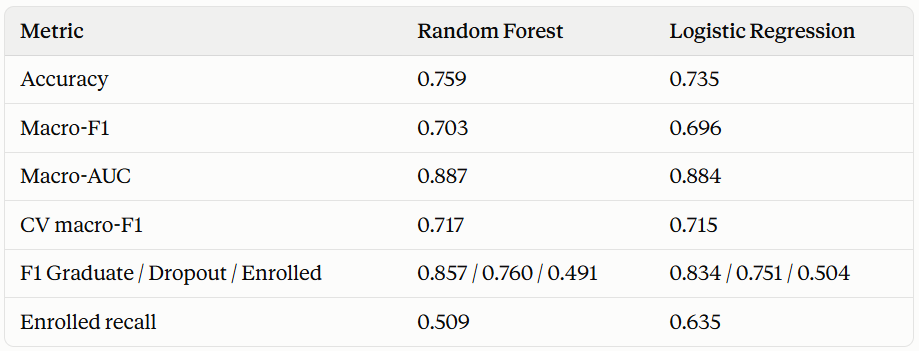

Random Forest is better on accuracy (by about 2.4 percentage points), and slightly better on macro-AUC and on the Graduate and Dropout classes. On macro-F1 and cross-validation the two are almost tied (0.703 vs 0.696 and 0.717 vs 0.715), so the extra complexity of the forest buys little on the balanced metrics. Logistic Regression finds more Enrolled students (recall 0.635 vs 0.509), but with lower precision (0.417), so its Enrolled F1 is about the same (0.504 vs 0.491). Logistic Regression is also easier to interpret, since each coefficient shows a feature’s direction and size of effect, while the forest needs importance plots.

### 7.2 Limitations
- Data from a single institution and time period, so results may not generalise elsewhere.
- Class imbalance, with "Enrolled" under-represented.
- Strong dependence on 2nd-semester features, which are only available late.
- Impurity-based importances are biased toward features with many distinct values, and correlated features split importance.
- Random Forest is harder to explain to non-technical staff than a linear model.
- Test-set results come from a single random split.

### 7.3 Possible improvements and future work
- Try **resampling** (SMOTE) or **threshold tuning** for the "Enrolled" class.
- Compare **Gradient Boosting / XGBoost** or a stacked ensemble.
- Engineer new features (e.g. approval rate = approved / enrolled units, grade trend between semesters).
- Use **repeated or nested cross-validation** for more reliable estimates, and a wider hyperparameter search.
- Add **SHAP** values for better per-student explanations.
- Build a true **early-warning model** evaluated at several points in time.
- Examine **fairness** across gender, nationality and socioeconomic groups before any real-world use.

## 8. Contribution

| | **Member 1** | **Member 2** |
|---|---|---|
| **Name** | `Thuiyadura L.R` | `Nissanka H.M.D.P` |
| **Student ID** | `MS26923956` | `MS26930190` |
| **Algorithm** | `Logistic Regression` | `Random Forest` |
| **Notebook** | `logistic_regression.ipynb` | `random_forest.ipynb` |
| **GitHub branch** | `thuiyadura-lr-ms26923956` | `nissanka-hmdp-ms26930190` |

### Shared work (both members)
| Task | Done by |
|---|---|
| Dataset selection and checking it against the assignment requirements | Both |
| Agreeing the shared settings: `random_state=42`, stratified 80/20 train/test split, same one-hot encoding, macro-F1 for tuning | Both |
| Repository structure and branches (`main`, `final-development`, one branch per member) | Both |
| Comparison of the two algorithms (Table A, Table B and the discussion in Section 7.4) | Both |
| Final report (PDF), `members.txt` and `submission.txt` | Both |

### Individual work
| Task | Member 1: Logistic Regression | Member 2: Random Forest |
|---|---|---|
| Data cleansing, validity checks and outlier analysis | Missing values, duplicates, range and consistency checks, IQR outlier analysis, decision to keep outliers (limited by L2 regularisation) | Missing values, duplicates, IQR outlier analysis, decision to keep outliers (trees split on thresholds, so they are robust to outliers) |
| Exploratory analysis | Class distribution, boxplots by outcome, correlation matrix, VIF (multicollinearity) | Class distribution, boxplots by outcome, correlation matrix |
| Model-specific preprocessing | Standardisation of continuous features inside a `Pipeline` (no data leakage), PCA analysis | No scaling needed for trees; feature selection by importance instead of PCA |
| Algorithm background and justification | Logistic Regression (softmax, regularised loss, `C`) | Random Forest (decision tree and Gini impurity, bagging, random feature subsets, out-of-bag estimate) |
| Hyperparameter tuning | `GridSearchCV` over `C` and `class_weight`, scored by macro-F1 | `RandomizedSearchCV` (20 settings, 5-fold CV) over `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` and `class_weight`, scored by macro-F1 |
| Evaluation | Accuracy, per-class precision, recall and F1, macro-F1, confusion matrix, ROC-AUC, precision-recall curves, cross-validation | Accuracy, per-class precision, recall and F1, macro-F1, confusion matrix, ROC-AUC, cross-validation, out-of-bag accuracy |
| Model interpretation | Coefficients and odds ratios (risk and protective factors) | Impurity-based and permutation feature importance |
| Improvement experiments | Class weights, L1, PCA, early prediction, approval-rate features (all by CV), learning curve, Enrolled decision-rule tuning | Class weights, default hyperparameters, raw codes vs one-hot, top-30 features, early prediction, 1st-semester only, number of trees, learning curve |
| Critical analysis, limitations, future work | Written for Logistic Regression | Written for Random Forest |
| Statistical comparison of the two models | McNemar test, paired bootstrap and repeated cross-validation (Section 7.4), using the Random Forest settings from the results file | Tuned Random Forest and its results file (`results/random_forest_results.json`), plus the comparison table in its own notebook (Section 6.2) |
| Results file for the comparison | `results/logistic_regression_results.json` | `results/random_forest_results.json` |